# Assignment 02: EDA and Model Training

## Loading the Dataset
Loading data from csv and checking dimensions and quality of data.

In [170]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


df_raw = pd.read_csv("data/emp.csv")
df_raw.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [171]:
df_raw.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [172]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

Checking number of null and missing values in each column

In [173]:
df_raw.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [174]:
df_raw.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

Next, Checking which one of these text columns are categorical and how many values they have to determine if one hot encoding would be viable.

In [175]:
list_of_text_cols = df_raw.select_dtypes(include="str").columns.tolist()

for col in list_of_text_cols:
    print(df_raw[col].value_counts() , "\n")



Attrition
No     1233
Yes     237
Name: count, dtype: int64 

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64 

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64 

EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64 

Gender
Male      882
Female    588
Name: count, dtype: int64 

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64 

MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64 

Over18
Y    147

BusinessTravel and MaritialStatus can be Label encoded as the categories are related to each other. JobRole can be label encoded as it has too many categories and one hot encoding can unneceserily increase compute (Can experiment with One-Hot and Label encoding both to determine if increasing dimensions and extra compute is worth it.)  \
Over18, StandardHours, EmployeeNumber, EmployeeCount should be removed to reduce compute as they have no valuable data that could be used.  \
Rest can be converted with one hot encoding for training.

In [176]:
df_raw = df_raw.drop(columns=["Over18", "StandardHours", "EmployeeNumber", "EmployeeCount"])

In [177]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EnvironmentSatisfaction   1470 non-null   int64
 9   Gender                    1470 non-null   str  
 10  HourlyRate                1470 non-null   int64
 11  JobInvolvement            1470 non-null   int64
 12  JobLevel                  1470 non-null   int64
 13  JobRole                   1470 non-null   str  
 14  JobSatisfaction           1470 non-null   int64
 15

## Splitting data

Splitting data before checking linear correlation and visual non linear patterns to reduce Selection bias and Optimistic bias.

In [178]:
from sklearn.model_selection import train_test_split

df_train : pd.DataFrame
df_test : pd.DataFrame

df_train, df_test = train_test_split(df_raw, test_size=0.2, stratify=df_raw["Attrition"], random_state=42)

Chose to do stratified split to maintain the target class ratio, as there was class imbalance in our target feature. Checking class ratio in both sets below:

In [179]:
df_train["Attrition"].value_counts()

Attrition
No     986
Yes    190
Name: count, dtype: int64

In [18]:
986/190

5.189473684210526

In [19]:
df_test["Attrition"].value_counts()

Attrition
No     247
Yes     47
Name: count, dtype: int64

In [20]:
247/47

5.25531914893617

In [21]:
df_train.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1194,47,No,Travel_Rarely,1225,Sales,2,4,Life Sciences,1,1676,...,3,80,3,29,2,3,3,2,1,2
128,22,No,Travel_Rarely,594,Research & Development,2,1,Technical Degree,1,169,...,3,80,1,3,2,3,2,1,2,1
810,46,No,Travel_Rarely,406,Sales,3,1,Marketing,1,1124,...,4,80,1,23,3,3,12,9,4,9
478,25,No,Travel_Rarely,622,Sales,13,1,Medical,1,645,...,3,80,0,7,1,3,7,4,0,6
491,43,No,Travel_Frequently,1001,Research & Development,9,5,Medical,1,663,...,2,80,1,10,3,3,8,7,4,7


## EDA and Visual Patterns

array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'DailyRate'}>,
        <Axes: title={'center': 'DistanceFromHome'}>,
        <Axes: title={'center': 'Education'}>,
        <Axes: title={'center': 'EmployeeCount'}>],
       [<Axes: title={'center': 'EmployeeNumber'}>,
        <Axes: title={'center': 'EnvironmentSatisfaction'}>,
        <Axes: title={'center': 'HourlyRate'}>,
        <Axes: title={'center': 'JobInvolvement'}>,
        <Axes: title={'center': 'JobLevel'}>],
       [<Axes: title={'center': 'JobSatisfaction'}>,
        <Axes: title={'center': 'MonthlyIncome'}>,
        <Axes: title={'center': 'MonthlyRate'}>,
        <Axes: title={'center': 'NumCompaniesWorked'}>,
        <Axes: title={'center': 'PercentSalaryHike'}>],
       [<Axes: title={'center': 'PerformanceRating'}>,
        <Axes: title={'center': 'RelationshipSatisfaction'}>,
        <Axes: title={'center': 'StandardHours'}>,
        <Axes: title={'center': 'StockOptionLevel'}>,
        <Axe

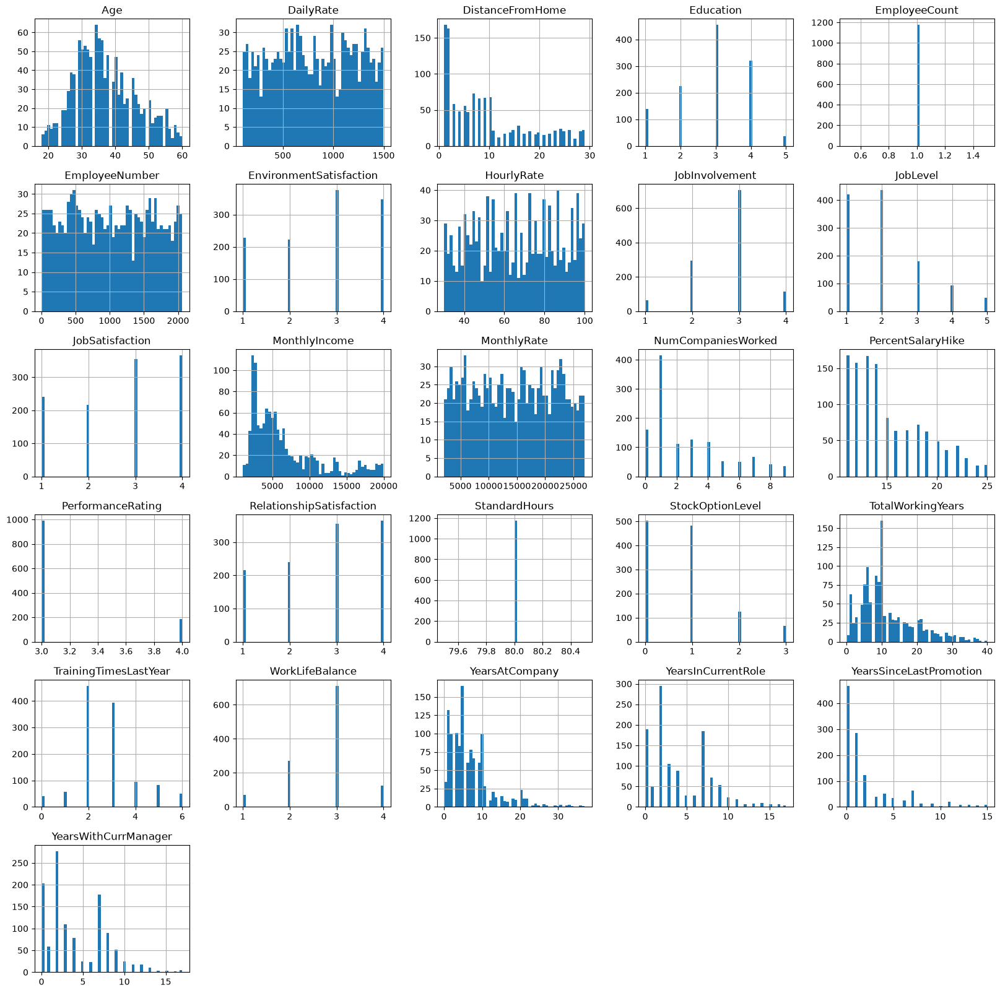

In [ ]:

df_train.hist(bins=50, figsize=(20,20))

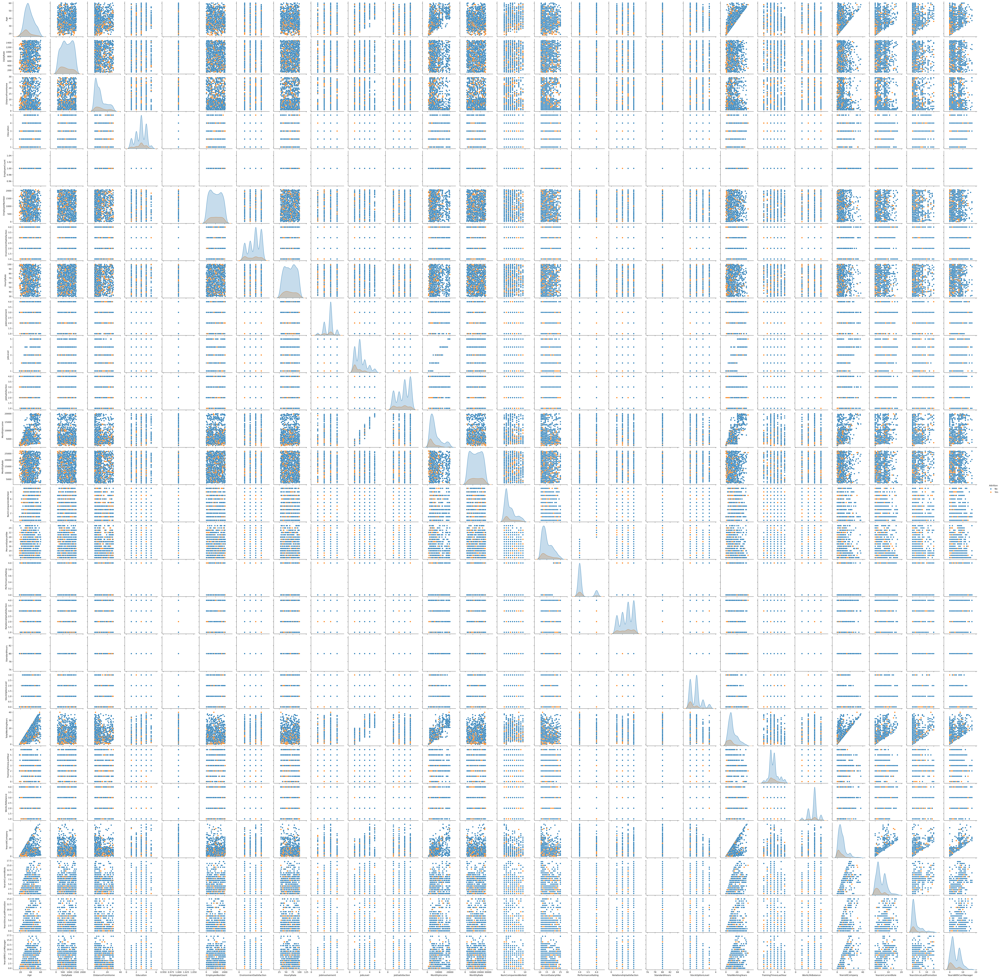

In [14]:
import seaborn as sns

sns.pairplot(df_train, hue="Attrition")

<Axes: xlabel='Attrition', ylabel='count'>

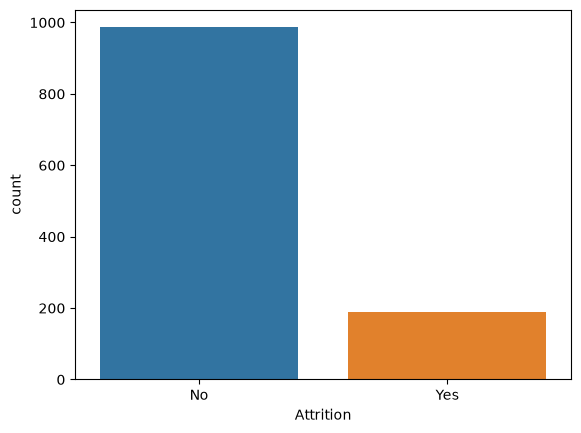

In [15]:
sns.countplot(df_train, x="Attrition", hue="Attrition")

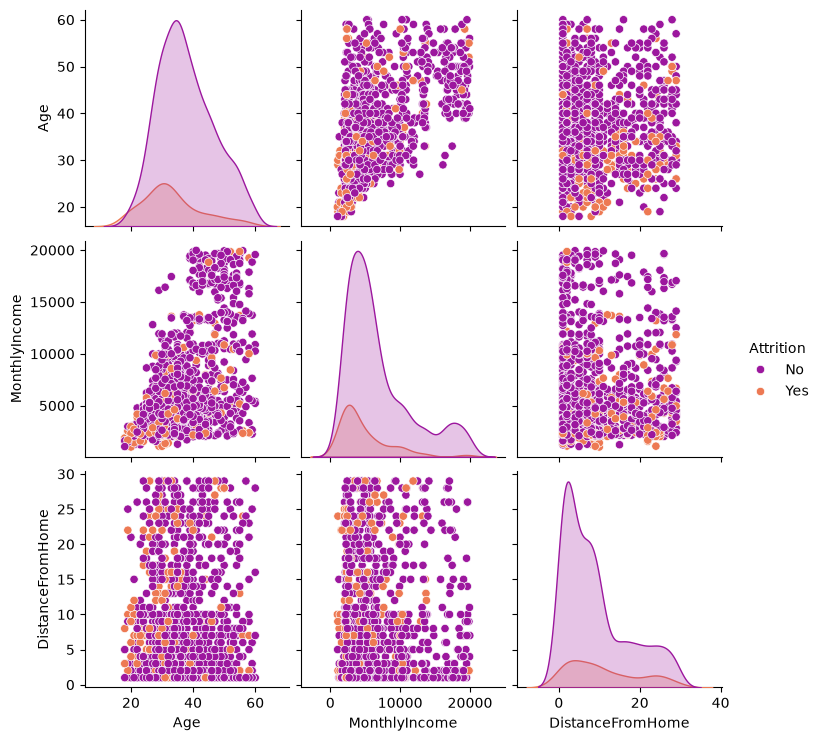

In [16]:
sns.pairplot(
    df_train[["Age", "MonthlyIncome", "DistanceFromHome", "Attrition"]],
    hue="Attrition",
    palette="plasma"
)

### EDA of relevant numerical values against Attrition

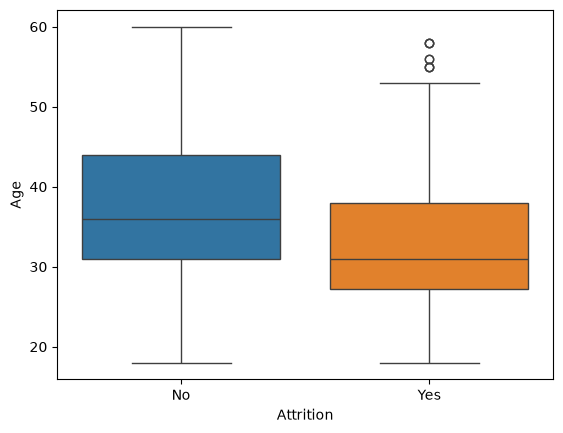

In [55]:
sns.boxplot(
    data=df_train,
    x="Attrition",
    y="Age",
    hue="Attrition",
)

plt.show()

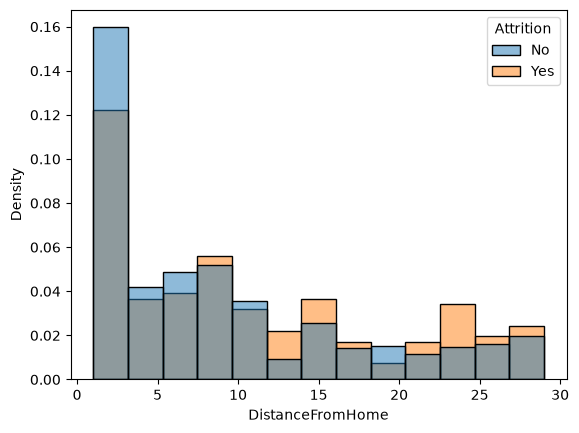

In [49]:
sns.histplot(x="DistanceFromHome", hue="Attrition", data=df_train, stat="density", common_norm=False)
plt.show()

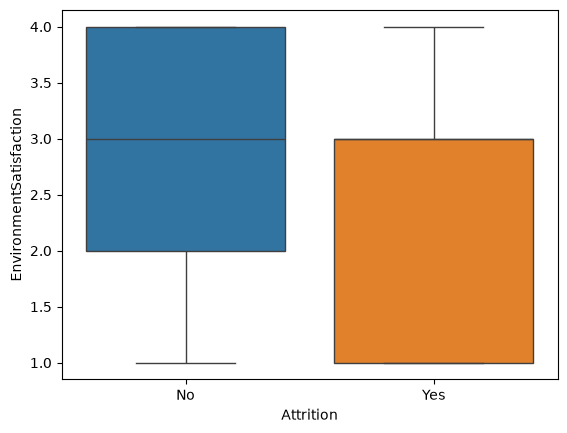

In [58]:
sns.boxplot(x="Attrition", y="EnvironmentSatisfaction", hue="Attrition", data=df_train)
plt.show()

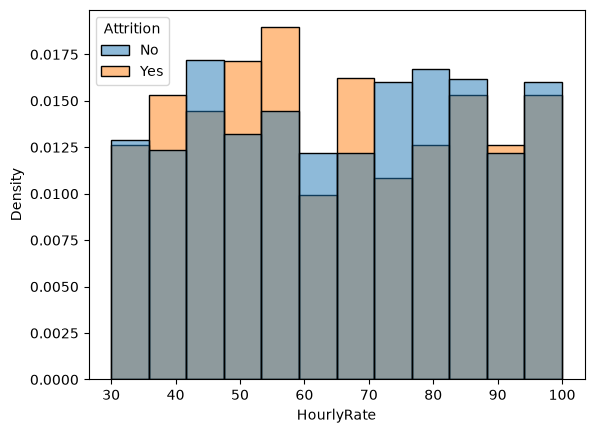

In [ ]:
sns.histplot(x="HourlyRate", hue="Attrition", data=df_train, stat="density", common_norm=False)
plt.show()

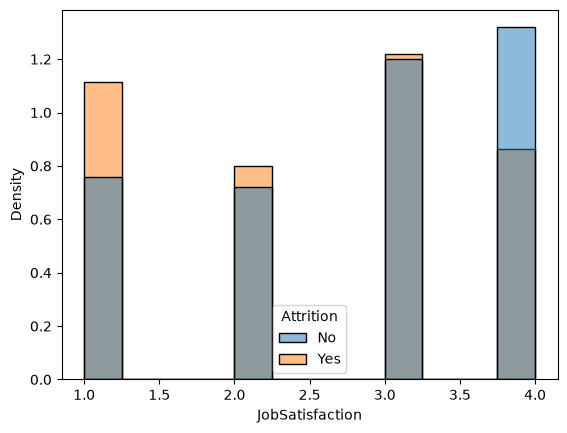

In [52]:
sns.histplot(x="JobSatisfaction", hue="Attrition", data=df_train, stat="density", common_norm=False)
plt.show()

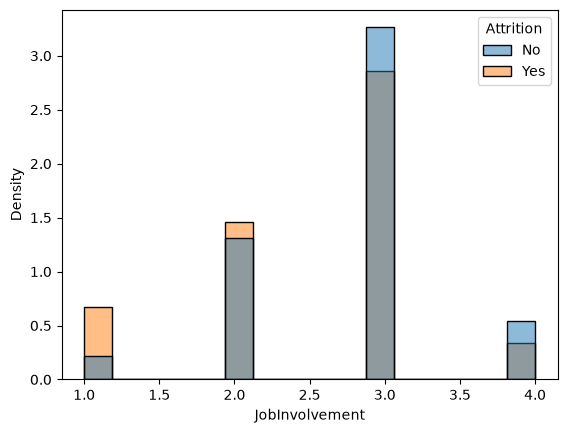

In [60]:
sns.histplot(x="JobInvolvement", hue="Attrition", data=df_train, stat="density", common_norm=False)
plt.show()

[]

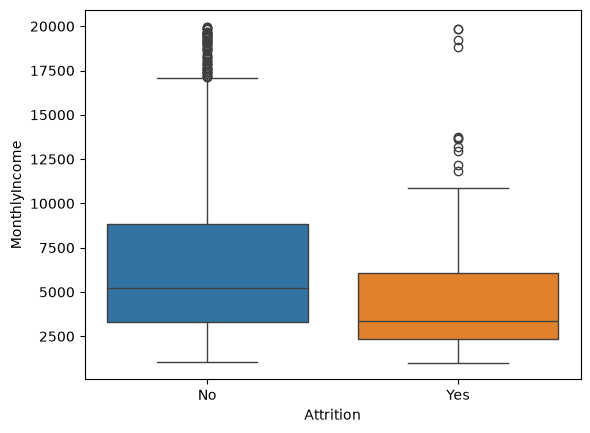

In [62]:
sns.boxplot(x="Attrition", y="MonthlyIncome", data=df_train, hue="Attrition")
plt.plot()

<Axes: xlabel='MonthlyIncome', ylabel='Density'>

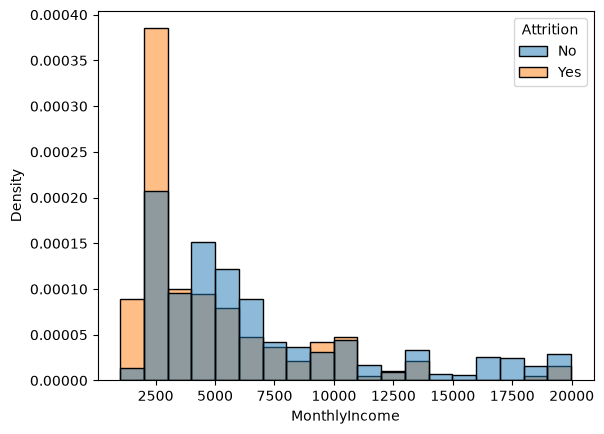

In [63]:
sns.histplot(x="MonthlyIncome", data=df_train, hue="Attrition", common_norm=False, stat="density")

<Axes: xlabel='YearsAtCompany', ylabel='Density'>

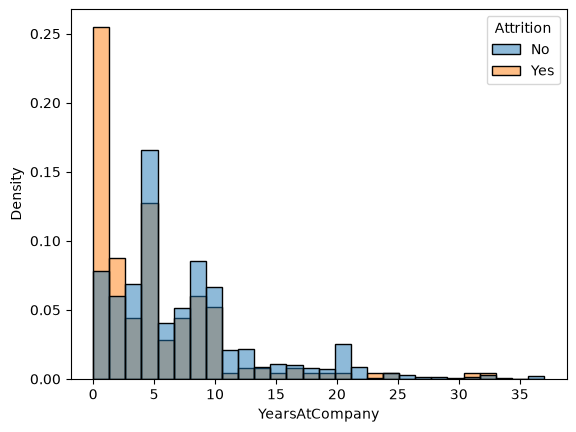

In [73]:
sns.histplot(x="YearsAtCompany", data=df_train, hue="Attrition", common_norm=False, stat="density")

<Axes: xlabel='Attrition', ylabel='YearsAtCompany'>

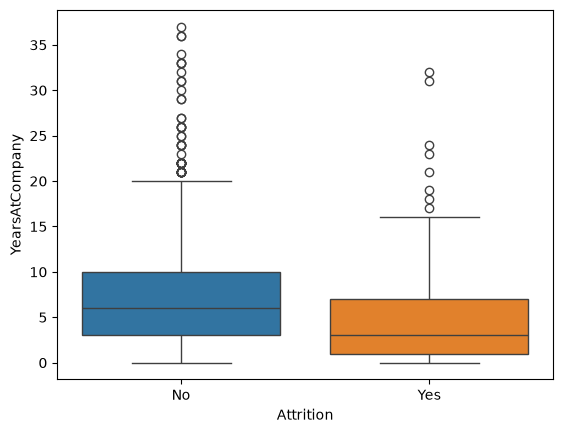

In [71]:
sns.boxplot(x="Attrition", y="YearsAtCompany", data=df_train, hue="Attrition")

<Axes: xlabel='YearsInCurrentRole', ylabel='Density'>

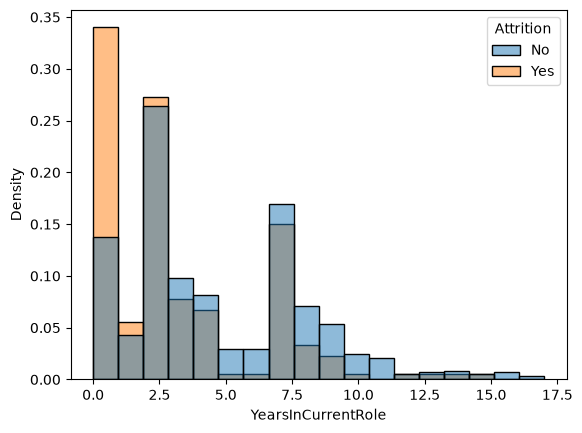

In [74]:
sns.histplot(x="YearsInCurrentRole", data=df_train, hue="Attrition", common_norm=False, stat="density")

<Axes: xlabel='Attrition', ylabel='YearsInCurrentRole'>

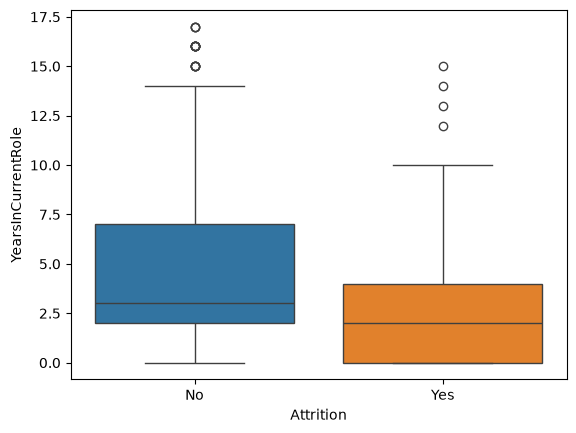

In [76]:
sns.boxplot(x="Attrition", y="YearsInCurrentRole", data=df_train, hue="Attrition",)

<Axes: xlabel='YearsSinceLastPromotion', ylabel='Density'>

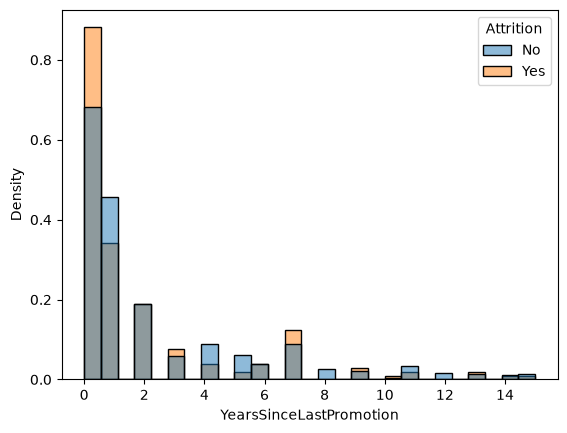

In [75]:
sns.histplot(x="YearsSinceLastPromotion", data=df_train, hue="Attrition", common_norm=False, stat="density")

### EDA of relevant categorical values against Attrition

In [77]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 1176 entries, 1194 to 1292
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1176 non-null   int64
 1   Attrition                 1176 non-null   str  
 2   BusinessTravel            1176 non-null   str  
 3   DailyRate                 1176 non-null   int64
 4   Department                1176 non-null   str  
 5   DistanceFromHome          1176 non-null   int64
 6   Education                 1176 non-null   int64
 7   EducationField            1176 non-null   str  
 8   EmployeeCount             1176 non-null   int64
 9   EmployeeNumber            1176 non-null   int64
 10  EnvironmentSatisfaction   1176 non-null   int64
 11  Gender                    1176 non-null   str  
 12  HourlyRate                1176 non-null   int64
 13  JobInvolvement            1176 non-null   int64
 14  JobLevel                  1176 non-null   int64
 15  

[]

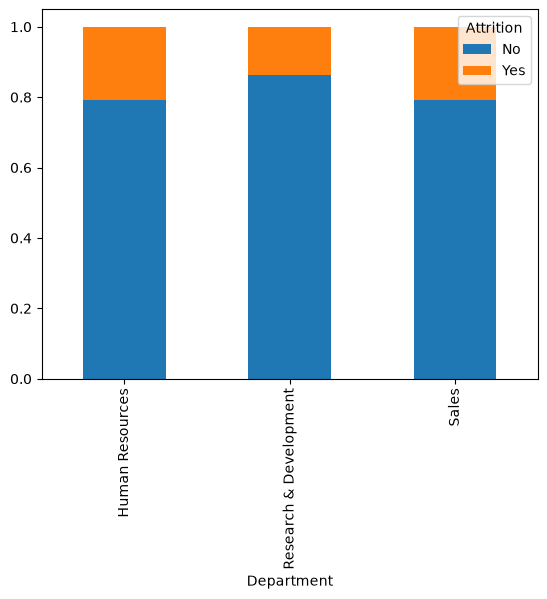

In [78]:
pd.crosstab(df_train["Department"], df_train["Attrition"], normalize="index").plot(kind="bar", stacked=True)
plt.plot()

<Axes: xlabel='Department', ylabel='count'>

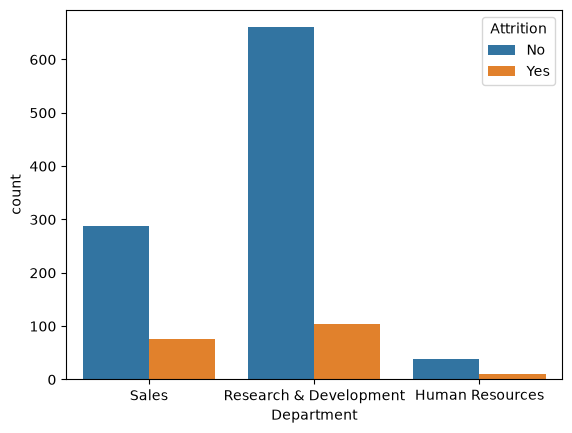

In [ ]:
sns.countplot(x="Department", hue="Attrition", data=df_train,)

<Axes: xlabel='Gender'>

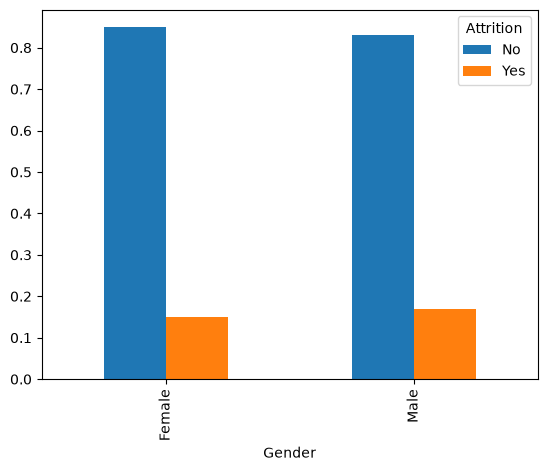

In [82]:
pd.crosstab(df_train["Gender"], df_train["Attrition"], normalize="index").plot(kind="bar")

[]

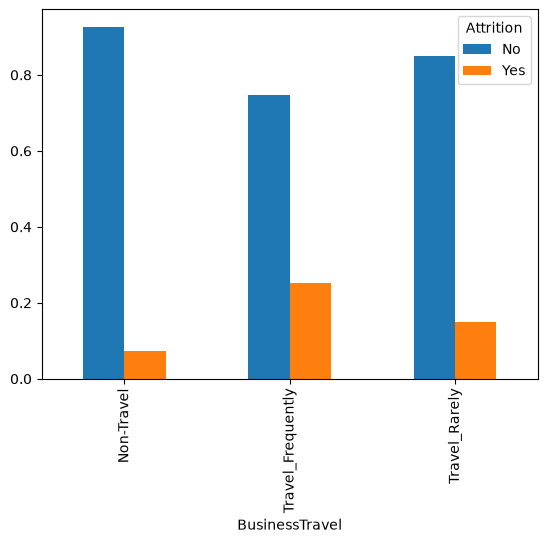

In [85]:
pd.crosstab(df_train["BusinessTravel"], df_train["Attrition"], normalize="index").plot(kind="bar")
plt.plot()

[]

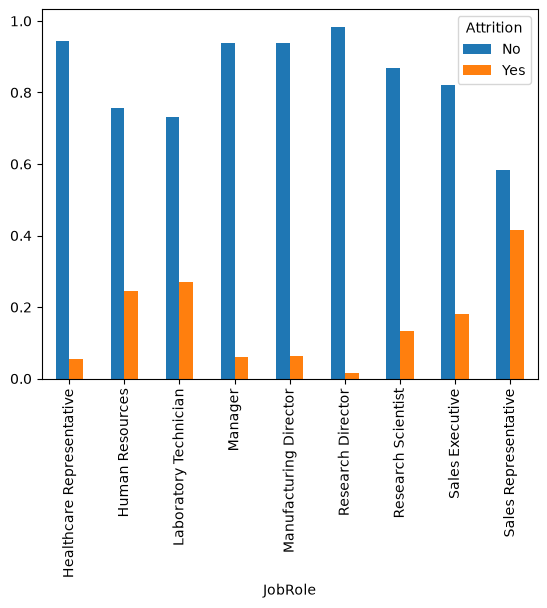

In [ ]:
pd.crosstab(df_train["JobRole"], df_train["Attrition"], normalize="index").plot(kind="bar")
plt.plot()

<Axes: xlabel='MaritalStatus'>

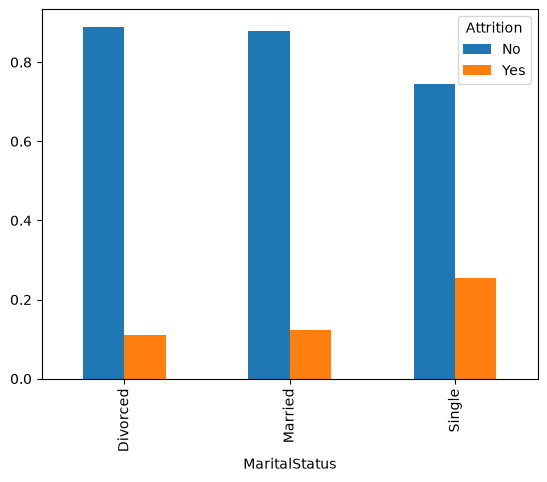

In [89]:
pd.crosstab(df_train["MaritalStatus"], df_train["Attrition"], normalize="index").plot(kind="bar")

[]

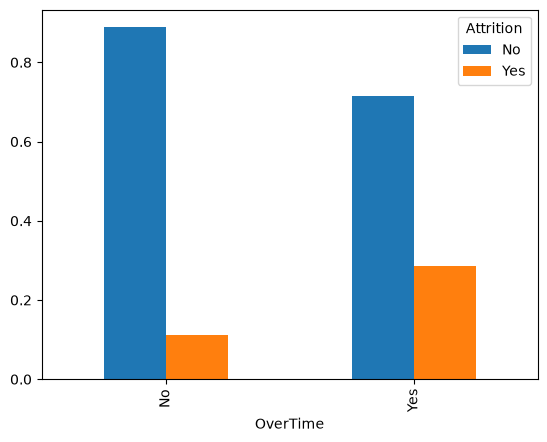

In [94]:
pd.crosstab(df_train["OverTime"], df_train["Attrition"], normalize="index").plot(kind="bar",)
plt.plot()

EDA of various numerical and categorical values prove that most of the features have some effect on attrition and most of the features have valuable information that our model will need. Only column that will be removed is Over18 because it has same value across the dataset.

## Creating training pipeline

Creating a training pipeline with imputing, scaling and encoding. So this single pipeline could be used for multiple experiments.

In [180]:
from sklearn.preprocessing import LabelEncoder

label_encoder =LabelEncoder()

df_train_x = df_train.drop(columns=["Attrition"])
df_train_y = np.asarray(label_encoder.fit_transform(df_train["Attrition"]))

df_test_x = df_test.drop(columns=["Attrition"])
df_test_y = np.asarray(label_encoder.transform(df_test["Attrition"]))



numerical_cols = df_train.select_dtypes(include="int64").columns.tolist()


In [181]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, OrdinalEncoder

simple_imputer_num = SimpleImputer(strategy="median")
simple_imputer_cat = SimpleImputer(strategy="most_frequent")
standard_scaler = StandardScaler()
one_hot_encoder = OneHotEncoder()
ordinal_encoder = OrdinalEncoder()

cat_onehot_pipeline = Pipeline([("simpleImputerCat", simple_imputer_cat), ("oneHotEncoder", one_hot_encoder)])
cat_label_pipeline = Pipeline([("simpleImputerCat", simple_imputer_cat), ("labelEncoder", ordinal_encoder)])
num_pipeline = Pipeline([("simpleImputerNum", simple_imputer_num), ("standardScaler", standard_scaler)])

final_model = ColumnTransformer([("catLabel", cat_label_pipeline, ["BusinessTravel" ,"JobRole", "MaritalStatus"]),
                                 ("catOneHot", cat_onehot_pipeline, ["OverTime", "Gender", "Department", "EducationField"]),
                                 ("num", num_pipeline, numerical_cols)])




## Training Model

### Finding optimal no. of K

In [182]:
from sklearn.neighbors import KNeighborsClassifier

final_pipeline = Pipeline([("model",final_model), ("knn", KNeighborsClassifier())])



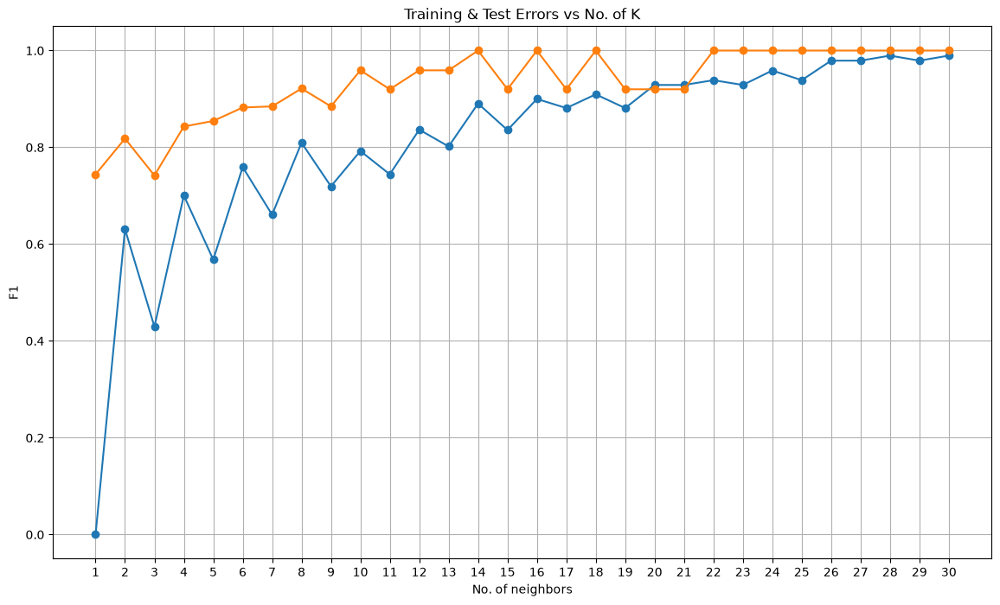

In [183]:
from sklearn.metrics import f1_score

training_errors =[]
test_errors = []

k_values = range(1,31)

for k in k_values:
    final_pipeline.set_params(knn__n_neighbors=k)
    final_pipeline.fit(df_train_x, df_train_y)
    
    train_pred = final_pipeline.predict(df_train_x)
    test_pred = final_pipeline.predict(df_test_x)
    
    train_accuracy = f1_score(df_train_y, train_pred)
    test_accuracy = f1_score(df_test_y, test_pred)
    
    training_errors.append(1-train_accuracy)
    test_errors.append(1-test_accuracy)
    
plt.figure(figsize=(14,8))
plt.plot(k_values, training_errors, marker="o", label="Training error")
plt.plot(k_values, test_errors, marker="o", label="Test error")
plt.title("Training & Test Errors vs No. of K")
plt.xlabel("No. of neighbors")
plt.ylabel("F1")
plt.grid(True)
plt.xticks(k_values)
plt.show()
    
    

Most optimal k value according to the graph seems to be 9, as error somewhat stabilizes after that. I can go with 17 as well, but that would increase a lot of compute for very marginal improvement. So deciding with k=9 as optimal for now.

### Evaluating with K-Fold cross val on training set

In [184]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

final_pipeline.set_params(knn__n_neighbors=3)

kf = KFold(n_splits=5)

pred = cross_val_predict(final_pipeline, df_train_x, df_train_y)

confusion_mat = confusion_matrix(df_train_y, pred)



print("K-fold Evaluation on training data:")
print(classification_report(df_train_y, pred))


K-fold Evaluation on training data:
              precision    recall  f1-score   support

           0       0.86      0.96      0.91       986
           1       0.49      0.18      0.27       190

    accuracy                           0.84      1176
   macro avg       0.68      0.57      0.59      1176
weighted avg       0.80      0.84      0.81      1176



Text(50.83333333333333, 0.5, 'Actual')

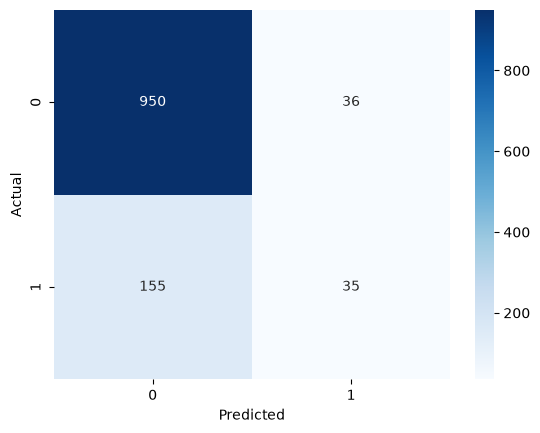

In [185]:
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Blues', )
plt.xlabel('Predicted')
plt.ylabel('Actual')

### Evaluating on test set

In [186]:
final_pipeline.set_params(knn__n_neighbors=3)

final_pipeline.fit(df_train_x, df_train_y)

pred = final_pipeline.predict(df_test_x)

confusion_mat = confusion_matrix(df_test_y, pred)



print("K-fold Evaluation on test data:")
print(classification_report(df_test_y, pred))

K-fold Evaluation on test data:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91       247
           1       0.53      0.17      0.26        47

    accuracy                           0.84       294
   macro avg       0.70      0.57      0.59       294
weighted avg       0.81      0.84      0.81       294



[]

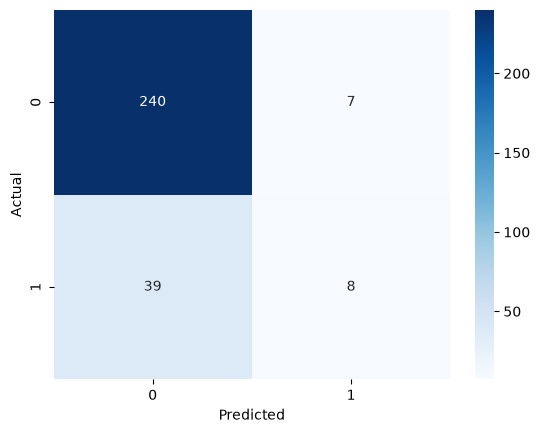

In [187]:
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Blues', )
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.plot()

## Hyperparameter tuning

In [191]:
from sklearn.model_selection import GridSearchCV

gs = GridSearchCV(final_pipeline, param_grid=[{"knn__n_neighbors": [3,5,7,9,11,13,15,17]}], scoring="f1")

gs.fit(df_train_x, df_train_y)

print(gs.best_params_)

{'knn__n_neighbors': 3}


In [192]:
grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["minkowski", "manhattan", "euclidean"],
    "knn__leaf_size": [15, 30, 45, 60],
    "knn__algorithm": ["auto", "ball_tree", "kd_tree", "brute"]
}

gs = GridSearchCV(final_pipeline, param_grid=grid, scoring="f1" , verbose=1, n_jobs=1, cv=5)

gs.fit(df_train_x, df_train_y)

print(gs.best_params_)
print(gs.best_score_)

Fitting 5 folds for each of 768 candidates, totalling 3840 fits
{'knn__algorithm': 'auto', 'knn__leaf_size': 15, 'knn__metric': 'minkowski', 'knn__n_neighbors': 3, 'knn__weights': 'uniform'}
0.2667952635599694


Hence, after above tuning of hyperparameters I will select the above configuration.

## Evaluating on test set after Hyperparameter Tuning

In [193]:
final_pipeline.set_params(knn__n_neighbors=3, knn__algorithm="auto", knn__leaf_size=15, knn__metric="minkowski", knn__weights="uniform")

final_pipeline.fit(df_train_x, df_train_y)

pred = final_pipeline.predict(df_test_x)

confusion_mat = confusion_matrix(df_test_y, pred)



print("K-fold Evaluation on test data:")
print(classification_report(df_test_y, pred))

K-fold Evaluation on test data:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91       247
           1       0.53      0.17      0.26        47

    accuracy                           0.84       294
   macro avg       0.70      0.57      0.59       294
weighted avg       0.81      0.84      0.81       294



[]

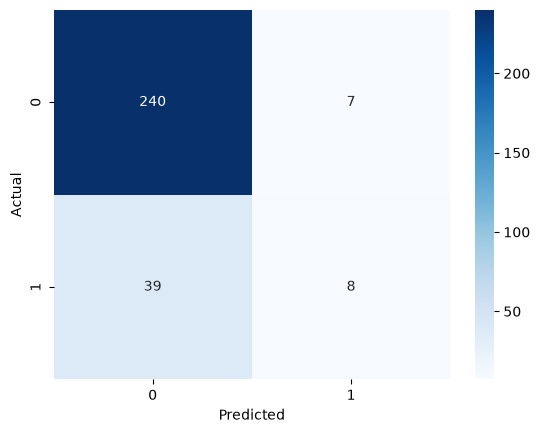

In [194]:
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Blues', )
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.plot()

Apparently, hyperparameter tuning did not have much impact on the model's performance. Despite achieving good accuracy, the model's overall performance is still mediocre, and it seems to be severely underfitting in terms of the problem we're trying to solve.

It also seems that KNN might not be the right choice for this kind of dataset, and there are a few reasons behind that:

1. Severe class imbalance: There is a significant imbalance in our target variable, "Attrition", with considerably more employees staying than leaving.

2. Lack of strong patterns: We couldn't identify strong patterns across the dataset. The data appears to be scattered, with considerable overlap between the two target classes.

3. High dimensionality: The dataset has a relatively large number of features, and almost none of them has a strong relationship with "Attrition". Most features seem to have only a weak individual relationship with the target variable.

These factors make it difficult for KNN to identify meaningful similarities between employees and accurately classify those who are likely to leave.

But it does not mean that this dataset and problem is hopeless, as the assignment ends here, I am ending my experimentation here. If i were to explore further, class imbalance reduction with SMOTE can be explored and experimented with. Also other models can also be experimented with, with and without SMOTE, Logistic regression, Random forest classifier and SVM can be experimented with this data and problemset.